### Part - A: Conceptual Understanding

1. What is Logistic Regression and why is it suitable for classification?
- Logistic Regression is a supervised machine learning algorithm used for classification. It predicts the probability of a class between 0 and 1. It is suitable for binary classification such as Low Risk (0) and High Risk (1).
2. Explain classification performance metrics and why accuracy alone is insufficient.
- Classification metrics include Accuracy, Precision, Recall, and F1-Score. Accuracy alone can be misleading when the dataset is imbalanced because a model may get high accuracy while performing poorly on the minority class.
3. Define Type-I Error and Type-II Error in the context of risk prediction.  
- Type-I Error (False Positive): Predicting a customer as High Risk when they are actually Low Risk.
- Type-II Error (False Negative): Predicting a customer as Low Risk when they are actually High Risk.
4. Explain Precision, Recall, F1-Score, TPR, and FPR.  
- Precision: Correct High Risk predictions out of all predicted High Risk cases.
- Recall (TPR): Correctly identified High Risk customers out of all actual High Risk customers.
- F1-Score: Harmonic mean of Precision and Recall.
- TPR: True Positive Rate = Recall.
- FPR: False Positive Rate = False Positives / Actual Negative cases.
5. What is AUC-ROC and how does it help in evaluating classifiers?
ROC curve shows the relationship between TPR and FPR at different thresholds. AUC represents the overall ability of a model to distinguish between Low Risk and High Risk customers. Higher AUC generally means better classification performance.
6. Why does imbalanced data create problems in classification models?
In imbalanced data, one class has many more samples than the other. The model may become biased toward the majority class and give high accuracy while failing to identify minority-class cases correctly.

### Part - B: Dataset Preparation and Understanding

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix,accuracy_score,precision_score,recall_score,
    f1_score)

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, f1_score, roc_auc_score

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_curve, roc_auc_score


In [4]:
df = pd.read_csv(r'D:\RW\RW_Exam\ML\PR-3\Risk_Alert.csv')
df.head()

,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0


In [5]:
X = df.drop(columns=['customer_id', 'risk_status'])
y = df['risk_status']

X['last_transaction_date'] = pd.to_datetime(
    X['last_transaction_date'],
    errors='coerce'
)

X['days_since_last_transaction'] = (
    pd.Timestamp.today() - X['last_transaction_date']
).dt.days

X = X.drop(columns=['last_transaction_date'])

X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Train: ", X_train.shape, "Test: ", X_test.shape)

Train:  (3680, 24) Test:  (920, 24)


In [6]:
imputer = KNNImputer(n_neighbors=5)

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Missing values after imputation:", X_train.isnull().sum().sum())

Training set: (3680, 24)
Testing set: (920, 24)
Missing values after imputation: 0


### Part - C: Baseline Classification Model

In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)


In [8]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

Confusion Matrix:
[[809   0]
 [  0 111]]

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0


In [9]:
TN, FP, FN, TP = cm.ravel()

print("(TN):", TN)
print("(FP) - Type-I Error:", FP)
print("(FN) - Type-II Error:", FN)
print("(TP):", TP)

(TN): 809
(FP) - Type-I Error: 0
(FN) - Type-II Error: 0
(TP): 111


### Part - D: Handling Imbalanced Data

Class Distribution:
risk_status
0    3234
1     446
Name: count, dtype: int64


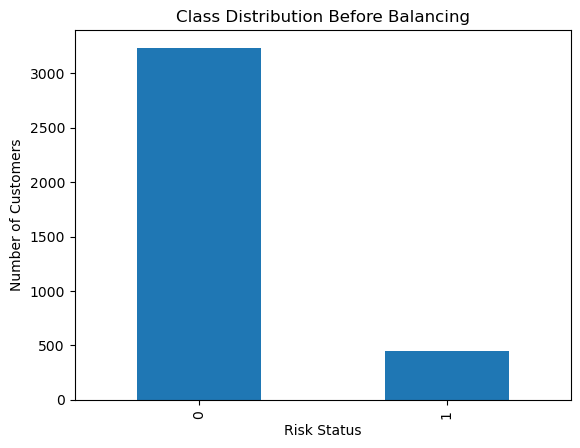

In [10]:
print("Class Distribution:")
print(y_train.value_counts())

y_train.value_counts().plot(kind='bar')
plt.title("Class Distribution Before Balancing")
plt.xlabel("Risk Status")
plt.ylabel("Number of Customers")
plt.show()


In [11]:
def evaluate_balanced_model(X_train_balanced, y_train_balanced, name):
    
    model = LogisticRegression(max_iter=2000)
    
    model.fit(X_train_balanced, y_train_balanced)
    
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    
    print("\n", name)
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))
    print("AUC-ROC:", round(auc, 4))
    
    return recall, f1, auc

In [13]:
under = RandomUnderSampler(random_state=42)

X_under, y_under = under.fit_resample(X_train_scaled,y_train)

print("After Under-Sampling:")
print(y_under.value_counts())

under_result = evaluate_balanced_model(X_under,y_under,"Under-Sampling")

After Under-Sampling:
risk_status
0    446
1    446
Name: count, dtype: int64

 Under-Sampling
Recall: 1.0
F1-Score: 0.9911
AUC-ROC: 1.0


In [ ]:
over = RandomOverSampler(random_state=42)
X_over, y_over = over.fit_resample(X_train_scaled,y_train)

print("After Over-Sampling:")
print(y_over.value_counts())

over_result = evaluate_balanced_model(X_over,y_over,"Over-Sampling")

After Over-Sampling:
risk_status
0    3234
1    3234
Name: count, dtype: int64

 Over-Sampling
Recall: 1.0
F1-Score: 0.9911
AUC-ROC: 1.0


In [ ]:
smote = SMOTE(random_state=42)

X_smote, y_smote = smote.fit_resample(X_train_scaled,y_train)
print("After SMOTE:")
print(y_smote.value_counts())

smote_result = evaluate_balanced_model(X_smote,y_smote,"SMOTE")

After SMOTE:
risk_status
0    3234
1    3234
Name: count, dtype: int64

 SMOTE
Recall: 1.0
F1-Score: 0.9911
AUC-ROC: 1.0


c:\Users\Priyansh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Priyansh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Priyansh\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Priyansh\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Priyansh\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _w

In [16]:
adasyn = ADASYN(random_state=42)

X_adasyn, y_adasyn = adasyn.fit_resample(X_train_scaled,y_train)
print("After ADASYN:")
print(y_adasyn.value_counts())

adasyn_result = evaluate_balanced_model(X_adasyn,y_adasyn,"ADASYN")

After ADASYN:
risk_status
1    3240
0    3234
Name: count, dtype: int64

 ADASYN
Recall: 1.0
F1-Score: 0.9823
AUC-ROC: 1.0


In [17]:
baseline_recall = recall_score(y_test, y_pred)
baseline_f1 = f1_score(y_test, y_pred)

baseline_prob = model.predict_proba(X_test_scaled)[:, 1]
baseline_auc = roc_auc_score(y_test, baseline_prob)

results = pd.DataFrame({
    "Method": [
        "Baseline",
        "Under-Sampling",
        "Over-Sampling",
        "SMOTE",
        "ADASYN"
    ],
    "Recall": [
        baseline_recall,
        under_result[0],
        over_result[0],
        smote_result[0],
        adasyn_result[0]
    ],
    "F1-Score": [
        baseline_f1,
        under_result[1],
        over_result[1],
        smote_result[1],
        adasyn_result[1]
    ],
    "AUC-ROC": [
        baseline_auc,
        under_result[2],
        over_result[2],
        smote_result[2],
        adasyn_result[2]
    ]
})

results

,Method,Recall,F1-Score,AUC-ROC
0,Baseline,1.0,1.000000,1.000000
1,Under-Sampling,1.0,0.991071,1.000000
2,Over-Sampling,1.0,0.991071,1.000000
3,SMOTE,1.0,0.991071,1.000000
4,ADASYN,1.0,0.982301,0.999989


### Part E: Tree-Based Classification Models

In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print("Decision Tree Results")
print("Accuracy :", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall   :", recall_score(y_test, dt_pred))
print("F1-Score :", f1_score(y_test, dt_pred))

Decision Tree Results
Accuracy : 0.9706521739130435
Precision: 0.8888888888888888
Recall   : 0.8648648648648649
F1-Score : 0.8767123287671232


In [23]:
dt_train_pred = dt_model.predict(X_train)

train_accuracy = accuracy_score(y_train, dt_train_pred)
test_accuracy = accuracy_score(y_test, dt_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy :", test_accuracy)

Training Accuracy: 1.0
Testing Accuracy : 0.9706521739130435


In [24]:
rf_model = RandomForestClassifier(n_estimators=100,random_state=42)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Results")
print("Accuracy :", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall   :", recall_score(y_test, rf_pred))
print("F1-Score :", f1_score(y_test, rf_pred))

Random Forest Results
Accuracy : 0.9945652173913043
Precision: 0.9907407407407407
Recall   : 0.963963963963964
F1-Score : 0.9771689497716894


In [25]:
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, dt_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1-Score": [
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.970652,0.888889,0.864865,0.876712
1,Random Forest,0.994565,0.990741,0.963964,0.977169


### Part F: Hyperparameter Tuning

In [ ]:
dt_params = {
    'max_depth': randint(2, 15),
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 10),
    'criterion': ['gini', 'entropy']
}

dt_random = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_distributions=dt_params,
    n_iter=20,
    cv=5,
    scoring='recall',
    random_state=42,
    n_jobs=-1
)

dt_random.fit(X_train, y_train)

print("Decision Tree Parameters:")
print(dt_random.best_params_)

print("CV Recall:", dt_random.best_score_)

Best Decision Tree Parameters:
{'criterion': 'entropy', 'max_depth': 13, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best CV Recall: 0.8968039950062423


In [34]:
from sklearn.ensemble import RandomForestClassifier

rf_params = {
    'n_estimators': randint(50, 300),
    'max_depth': randint(3, 20),
    'min_samples_split': randint(2, 15),
    'min_samples_leaf': randint(1, 8),
    'max_features': ['sqrt', 'log2']
}

rf_random = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions=rf_params,
    n_iter=20,
    cv=5,
    scoring='recall',
    random_state=42,
    n_jobs=-1
)

rf_random.fit(X_train, y_train)

print("Random Forest Parameters:")
print(rf_random.best_params_)

print("CV Recall:", rf_random.best_score_)

Best Random Forest Parameters:
{'max_depth': 19, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'min_samples_split': 11, 'n_estimators': 269}
Best CV Recall: 0.9260174781523096


In [ ]:
best_rf = rf_random.best_params_

rf_grid_params = {
    'n_estimators': [
        max(50, best_rf['n_estimators'] - 50),
        best_rf['n_estimators'],
        best_rf['n_estimators'] + 50
    ],
    'max_depth': [
        max(3, best_rf['max_depth'] - 2),
        best_rf['max_depth'],
        best_rf['max_depth'] + 2
    ],
    'min_samples_split': [
        max(2, best_rf['min_samples_split'] - 2),
        best_rf['min_samples_split'],
        best_rf['min_samples_split'] + 2
    ],
    'min_samples_leaf': [
        max(1, best_rf['min_samples_leaf'] - 1),
        best_rf['min_samples_leaf'],
        best_rf['min_samples_leaf'] + 1
    ],
    'max_features': [best_rf['max_features']]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=rf_grid_params,
    cv=5,
    scoring='recall',
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Tuned Random Forest Parameters:")
print(rf_grid.best_params_)

Best Tuned Random Forest Parameters:
{'max_depth': 17, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 11, 'n_estimators': 219}


In [36]:
rf_pred = rf_model.predict(X_test)
rf_tuned_pred = rf_grid.predict(X_test)

comparison = pd.DataFrame({
    "Model": [
        "Random Forest (Untuned)",
        "Random Forest (Tuned)"
    ],
    "Accuracy": [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, rf_tuned_pred)
    ],
    "Precision": [
        precision_score(y_test, rf_pred),
        precision_score(y_test, rf_tuned_pred)
    ],
    "Recall": [
        recall_score(y_test, rf_pred),
        recall_score(y_test, rf_tuned_pred)
    ],
    "F1-Score": [
        f1_score(y_test, rf_pred),
        f1_score(y_test, rf_tuned_pred)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest (Untuned),0.994565,0.990741,0.963964,0.977169
1,Random Forest (Tuned),0.996739,0.990909,0.981982,0.986425


### Part G: Model Evaluation & ROC Analysis

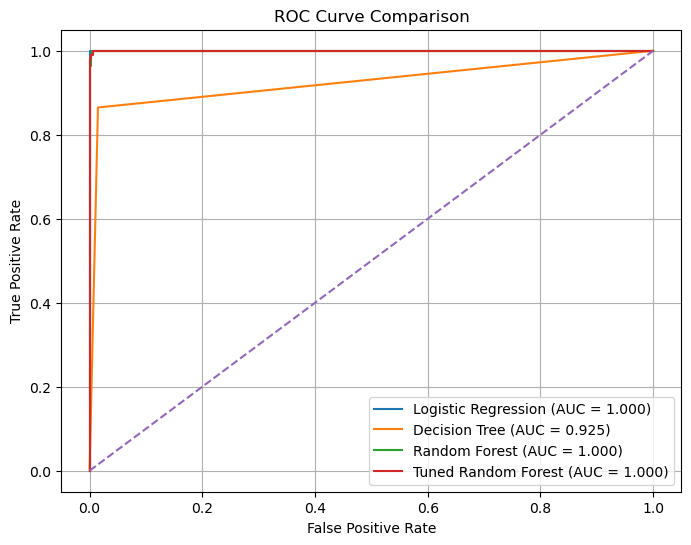

In [38]:
logistic_prob = model.predict_proba(X_test_scaled)[:, 1]

dt_prob = dt_model.predict_proba(X_test)[:, 1]
rf_prob = rf_model.predict_proba(X_test)[:, 1]
tuned_rf_prob = rf_grid.predict_proba(X_test)[:, 1]

fpr_log, tpr_log, _ = roc_curve(y_test, logistic_prob)
fpr_dt, tpr_dt, _ = roc_curve(y_test, dt_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)
fpr_tuned_rf, tpr_tuned_rf, _ = roc_curve(y_test, tuned_rf_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr_log, tpr_log,label=f"Logistic Regression (AUC = {roc_auc_score(y_test, logistic_prob):.3f})")

plt.plot(fpr_dt, tpr_dt,label=f"Decision Tree (AUC = {roc_auc_score(y_test, dt_prob):.3f})")

plt.plot(fpr_rf, tpr_rf,label=f"Random Forest (AUC = {roc_auc_score(y_test, rf_prob):.3f})")

plt.plot(fpr_tuned_rf, tpr_tuned_rf,label=f"Tuned Random Forest (AUC = {roc_auc_score(y_test, tuned_rf_prob):.3f})")

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()

In [39]:
auc_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "AUC-ROC": [
        roc_auc_score(y_test, logistic_prob),
        roc_auc_score(y_test, dt_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, tuned_rf_prob)
    ]
})

auc_results

,Model,AUC-ROC
0,Logistic Regression,1.000000
1,Decision Tree,0.925016
2,Random Forest,0.999900
3,Tuned Random Forest,0.999911


In [40]:
final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, rf_tuned_pred)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, rf_tuned_pred)
    ],
    "AUC-ROC": [
        roc_auc_score(y_test, logistic_prob),
        roc_auc_score(y_test, dt_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, tuned_rf_prob)
    ]
})

display(final_results)

best_model = final_results.loc[
    final_results["Recall"].idxmax()
]

print("Best Model:")
print(best_model)

,Model,Recall,F1-Score,AUC-ROC
0,Logistic Regression,1.000000,1.000000,1.000000
1,Decision Tree,0.864865,0.876712,0.925016
2,Random Forest,0.963964,0.977169,0.999900
3,Tuned Random Forest,0.981982,0.986425,0.999911


Best Model:
Model       Logistic Regression
Recall                      1.0
F1-Score                    1.0
AUC-ROC                     1.0
Name: 0, dtype: object


## Q26. Final Analysis & Reporting

1. Best Classification Model and Justification

- The final classification model is selected based on its performance, especially **Recall**. Since the main business objective is to identify as many high-risk customers as possible, a model with higher Recall is preferred. This helps reduce False Negative (Type-II) errors.

2. Impact of Imbalance Handling Techniques

- Under-Sampling, Over-Sampling, SMOTE, and ADASYN were applied to handle class imbalance. Their performance was compared using Recall, F1-Score, and AUC-ROC. These techniques help improve the model's ability to identify the minority High Risk class.

3. Comparison of Performance Metrics

- The models were compared using Accuracy, Precision, Recall, F1-Score, and AUC-ROC. Accuracy alone is not sufficient for this problem because the dataset is imbalanced. Therefore, Recall and AUC-ROC were given more importance.

4. Business Interpretation of False Positives and False Negatives

- **False Positive (Type-I Error):** A Low Risk customer is incorrectly predicted as High Risk. This may result in unnecessary warnings or additional verification.

- **False Negative (Type-II Error):** A High Risk customer is incorrectly predicted as Low Risk. This is more serious because the bank may fail to take preventive action against a risky customer.

Therefore, the final model should prioritize **high Recall and fewer False Negatives**.